# Stock-Market-ML-Predictor: 02. Define Targets

**Policy:**
- Train and Val splits: all base quantities and all 7 θ rules computed here.
- **Test split is LOCKED** — no targets computed on test. Only regime metadata is shown.
- Q1 thresholds are computed **once from Train rows only** and frozen.
- Rolling sigma (W=288) is **causal** — uses only past returns at every time step.
- All numbers in this notebook are freshly computed from `clean.csv`. No prior-session figures are reused.


In [1]:
import sys
from pathlib import Path

ML_DIR = Path(r"c:\B.TECH\Academics\SEMESTER V\03 Machine Learning\.ML LABs\Project\Stock-Market-ML-Indicator\ML")
if str(ML_DIR) not in sys.path:
    sys.path.insert(0, str(ML_DIR))

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

from src import config
from src.io_utils import load_clean_market_data_csv
from src.splitting import get_train_data, get_val_data, get_test_data, analyze_market_regimes
from src.labels import (
    COST, RULES, CANDIDATE_HORIZONS,
    compute_q1_thresholds,
    compute_all_targets,
    create_label_summary,
    floor_binding_report,
)

FIGURES_DIR = config.FIGURES_DIR
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.float_format", "{:.4f}".format)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 120)
print("Imports OK. COST c =", COST)


Imports OK. COST c = 0.0023


In [2]:
df = load_clean_market_data_csv()
print(f"Loaded clean.csv: {len(df):,} rows | {df.index[0]} → {df.index[-1]}")

train_df = get_train_data(df)
val_df   = get_val_data(df)

print(f"\nSplit counts (expected 220,953 / 47,347 / 49,940):")
print(f"  Train : {len(train_df):>7,} rows | {train_df.index[0]} → {train_df.index[-1]}")
print(f"  Val   : {len(val_df):>7,} rows | {val_df.index[0]} → {val_df.index[-1]}")

# Test split size from config (metadata only — do NOT load data)
n_test = config.SPLIT_BOUNDARIES["test"]["expected_candles"]
test_start = config.SPLIT_BOUNDARIES["test"]["start"]
test_end   = config.SPLIT_BOUNDARIES["test"]["end"]
print(f"  Test  : {n_test:>7,} rows | {test_start} → {test_end}  [LOCKED — not loaded]")

assert len(train_df) == 220_953, f"Train count mismatch: {len(train_df)}"
assert len(val_df)   ==  47_347, f"Val count mismatch: {len(val_df)}"
print("\nSplit size assertions: PASSED")


Loaded clean.csv: 318,240 rows | 2023-11-01 00:00:00+00:00 → 2026-11-09 23:55:00+00:00

Split counts (expected 220,953 / 47,347 / 49,940):
  Train : 220,953 rows | 2023-11-01 00:00:00+00:00 → 2025-12-07 04:40:00+00:00
  Val   :  47,347 rows | 2025-12-07 04:45:00+00:00 → 2026-05-20 14:15:00+00:00
  Test  :  49,940 rows | 2026-05-20 14:20:00+00:00 → 2026-11-09 23:55:00+00:00  [LOCKED — not loaded]

Split size assertions: PASSED


In [3]:
print("=" * 60)
print("Q1 THRESHOLDS — computed from TRAIN rows only, then frozen")
print("=" * 60)

q1 = compute_q1_thresholds(train_df, horizons=CANDIDATE_HORIZONS, cost=COST)

rows = []
for N in CANDIDATE_HORIZONS:
    up   = q1[f"q1_up_{N}"]
    down = q1[f"q1_down_{N}"]
    floor_up   = abs(up   - COST) < 1e-10
    floor_down = abs(down - COST) < 1e-10
    rows.append({
        "N": N,
        "θ_up (%)":    round(up   * 100, 4),
        "θ_down (%)":  round(down * 100, 4),
        "floor_up":    "YES (≡ S1)" if floor_up   else "no",
        "floor_down":  "YES (≡ S1)" if floor_down else "no",
    })

q1_table = pd.DataFrame(rows).set_index("N")
print(q1_table.to_string())
print()
print(f"NOTE: When floor binds, Q1 is identical to S1 (θ = c = {COST*100:.2f}%).")
print("This means the median move in the train set is smaller than round-trip cost.")
print("All such configurations will likely have very few Neutral labels (most moves")
print("are classified Up or Down with the floor threshold).")


2026-11-11 18:09:27 | INFO     | labels | Q1 N= 2: raw_up=0.0934% raw_down=0.0909% → θ_up=0.2300% θ_down=0.2300% (floor binds: up=True, down=True)


2026-11-11 18:09:27 | INFO     | labels | Q1 N= 3: raw_up=0.1136% raw_down=0.1104% → θ_up=0.2300% θ_down=0.2300% (floor binds: up=True, down=True)


2026-11-11 18:09:27 | INFO     | labels | Q1 N= 6: raw_up=0.1561% raw_down=0.1532% → θ_up=0.2300% θ_down=0.2300% (floor binds: up=True, down=True)


2026-11-11 18:09:27 | INFO     | labels | Q1 N=12: raw_up=0.2182% raw_down=0.2104% → θ_up=0.2300% θ_down=0.2300% (floor binds: up=True, down=True)


Q1 THRESHOLDS — computed from TRAIN rows only, then frozen
    θ_up (%)  θ_down (%)    floor_up  floor_down
N                                               
2     0.2300      0.2300  YES (≡ S1)  YES (≡ S1)
3     0.2300      0.2300  YES (≡ S1)  YES (≡ S1)
6     0.2300      0.2300  YES (≡ S1)  YES (≡ S1)
12    0.2300      0.2300  YES (≡ S1)  YES (≡ S1)

NOTE: When floor binds, Q1 is identical to S1 (θ = c = 0.23%).
This means the median move in the train set is smaller than round-trip cost.
All such configurations will likely have very few Neutral labels (most moves
are classified Up or Down with the floor threshold).


In [4]:
print("Computing targets on Train split...")
train_targets = compute_all_targets(
    train_df, train_df=train_df,
    horizons=CANDIDATE_HORIZONS, cost=COST, q1_thresholds=q1
)
print(f"  Train targets shape: {train_targets.shape}")

print("Computing targets on Val split (Q1 thresholds frozen from Train)...")
val_targets = compute_all_targets(
    val_df, train_df=train_df,
    horizons=CANDIDATE_HORIZONS, cost=COST, q1_thresholds=q1
)
print(f"  Val targets shape: {val_targets.shape}")
print("Done.")


Computing targets on Train split...


  Train targets shape: (220953, 140)
Computing targets on Val split (Q1 thresholds frozen from Train)...
  Val targets shape: (47347, 140)
Done.


In [5]:
print("=" * 70)
print("CLASS BALANCE: Up / Down / Neutral / Invalid per Horizon × Rule × Split")
print("=" * 70)

train_summary = create_label_summary(train_targets, "train")
val_summary   = create_label_summary(val_targets,   "val")
balance = pd.concat([train_summary, val_summary], ignore_index=True)

display_cols = ["split","horizon","rule","n_valid","n_up","n_down","n_neutral",
                "n_invalid","pct_up","pct_down","pct_neutral","pct_invalid"]
print(balance[display_cols].to_string(index=False))


CLASS BALANCE: Up / Down / Neutral / Invalid per Horizon × Rule × Split


split  horizon rule  n_valid  n_up  n_down  n_neutral  n_invalid  pct_up  pct_down  pct_neutral  pct_invalid
train        2   S1   220951 18945   18169     183837          2  8.5700    8.2200      83.2000       0.0000
train        2   S2   220951 11457   11202     198292          2  5.1900    5.0700      89.7400       0.0000
train        2   Q1   220951 18945   18169     183837          2  8.5700    8.2200      83.2000       0.0000
train        2   V1   220951 18790   18029     184132          2  8.5000    8.1600      83.3400       0.0000
train        2   V2   220951 15921   15347     189683          2  7.2100    6.9500      85.8500       0.0000
train        2   A1   220951 18945   11202     190804          2  8.5700    5.0700      86.3600       0.0000
train        2   A2   220951 11457   18169     191325          2  5.1900    8.2200      86.5900       0.0000
train        2  F05   220951 77999   77133      65819          2 35.3000   34.9100      29.7900       0.0000
train        2  F10

In [6]:
print("=" * 60)
print("θ THRESHOLDS per horizon × rule (Train, row-constant rules shown as scalars)")
print("=" * 60)

rows = []
for N in CANDIDATE_HORIZONS:
    for rule in RULES:
        col_up   = f"theta_up_{N}_{rule}"
        col_down = f"theta_down_{N}_{rule}"
        if col_up not in train_targets.columns:
            continue
        tu = train_targets[col_up]
        td = train_targets[col_down]
        rows.append({
            "N": N, "Rule": rule,
            "θ_up min (%)":  round(tu.min()  * 100, 4),
            "θ_up max (%)":  round(tu.max()  * 100, 4),
            "θ_up mean (%)": round(tu.mean() * 100, 4),
            "θ_down min (%)":  round(td.min()  * 100, 4),
            "θ_down max (%)":  round(td.max()  * 100, 4),
        })

theta_table = pd.DataFrame(rows)
print(theta_table.to_string(index=False))


θ THRESHOLDS per horizon × rule (Train, row-constant rules shown as scalars)


 N Rule  θ_up min (%)  θ_up max (%)  θ_up mean (%)  θ_down min (%)  θ_down max (%)
 2   S1        0.2300        0.2300         0.2300          0.2300          0.2300
 2   S2        0.3000        0.3000         0.3000          0.3000          0.3000
 2   Q1        0.2300        0.2300         0.2300          0.2300          0.2300
 2   V1        0.2300        0.4787         0.2310          0.2300          0.4787
 2   V2        0.2300        0.9575         0.2513          0.2300          0.9575
 2   A1        0.2300        0.2300         0.2300          0.3000          0.3000
 2   A2        0.3000        0.3000         0.3000          0.2300          0.2300
 2  F05        0.0500        0.0500         0.0500          0.0500          0.0500
 2  F10        0.1000        0.1000         0.1000          0.1000          0.1000
 2  F15        0.1500        0.1500         0.1500          0.1500          0.1500
 3   S1        0.2300        0.2300         0.2300          0.2300          0.2300
 3  

In [7]:
print('=' * 80)
print('EXTRA TRADABLE ROWS AND SUB-COST LOSS SHARE (Train Split)')
print('=' * 80)

subcost_records = []
for N in CANDIDATE_HORIZONS:
    valid = train_targets[f'has_valid_target_{N}']
    fwd_ret = train_targets[f'fwd_ret_{N}'][valid]
    abs_ret = fwd_ret.abs()
    
    # Baseline S1 (c = 0.23%)
    tgt_s1 = train_targets[f'target_{N}_S1'][valid]
    n_act_s1 = int((tgt_s1 != 0.0).sum())
    
    for rule in ['S1', 'F15', 'F10', 'F05']:
        col = f'target_{N}_{rule}'
        tgt = train_targets[col][valid]
        n_act = int((tgt != 0.0).sum())
        pct_act = n_act / len(valid) * 100.0
        extra_rows = n_act - n_act_s1
        extra_pct = (extra_rows / n_act_s1 * 100.0) if n_act_s1 > 0 else 0.0
        
        # Sub-cost signals: active signal where move < roundtrip cost c (0.23%)
        sub_cost_active = int(((tgt != 0.0) & (abs_ret < COST)).sum())
        sub_cost_loss_share = (sub_cost_active / n_act * 100.0) if n_act > 0 else 0.0
        
        subcost_records.append({
            'horizon': N,
            'rule': rule,
            'active_rows': n_act,
            'active_pct': round(pct_act, 2),
            'extra_rows_vs_S1': extra_rows,
            'extra_pct_vs_S1': round(extra_pct, 2),
            'sub_cost_loss_rows': sub_cost_active,
            'sub_cost_loss_share_pct': round(sub_cost_loss_share, 2),
        })

df_subcost = pd.DataFrame(subcost_records)
print(df_subcost.to_string(index=False))

print('\n' + '=' * 80)
print('BIG_MOVE_N TARGET SUMMARY (Train Split)')
print('=' * 80)
bm_records = []
for N in CANDIDATE_HORIZONS:
    valid = train_targets[f'has_valid_target_{N}']
    bm = train_targets[f'big_move_{N}'][valid]
    n_ones = int((bm == 1.0).sum())
    n_zeros = int((bm == 0.0).sum())
    bm_records.append({
        'horizon': N,
        'valid_candles': len(valid),
        'big_move_1 (moves > c)': n_ones,
        'big_move_0 (moves <= c)': n_zeros,
        'share_big_move_pct': round(n_ones / len(valid) * 100.0, 2),
    })
print(pd.DataFrame(bm_records).to_string(index=False))


EXTRA TRADABLE ROWS AND SUB-COST LOSS SHARE (Train Split)


 horizon rule  active_rows  active_pct  extra_rows_vs_S1  extra_pct_vs_S1  sub_cost_loss_rows  sub_cost_loss_share_pct
       2   S1        37114     16.8000                 0           0.0000                   0                   0.0000
       2  F15        69031     31.2400             31917          86.0000               31917                  46.2400
       2  F10       103514     46.8500             66400         178.9100               66400                  64.1500
       2  F05       155132     70.2100            118018         317.9900              118018                  76.0800
       3   S1        50030     22.6400                 0           0.0000                   0                   0.0000
       3  F15        85123     38.5300             35093          70.1400               35093                  41.2300
       3  F10       119621     54.1400             69591         139.1000               69591                  58.1800
       3  F05       165904     75.0900          



BIG_MOVE_N TARGET SUMMARY (Train Split)
 horizon  valid_candles  big_move_1 (moves > c)  big_move_0 (moves <= c)  share_big_move_pct
       2         220953                   37114                   183837             16.8000
       3         220953                   50030                   170920             22.6400
       6         220953                   76486                   144461             34.6200
      12         220953                  104535                   116406             47.3100


In [8]:
print("=" * 60)
print("FLOOR BINDING REPORT (Q1 and V rules, Train split)")
print(f"Floor at c = {COST*100:.2f}%")
print("=" * 60)

fb = floor_binding_report(train_targets, q1, horizons=CANDIDATE_HORIZONS, cost=COST)
print(fb.to_string(index=False))


FLOOR BINDING REPORT (Q1 and V rules, Train split)
Floor at c = 0.23%
 horizon    rule  n_valid floor_binds_all  theta                            note  n_floor_bound  pct_floor_bound
       2   Q1_up   220951            True 0.2300 θ=c=0.23% (floor always active)            NaN              NaN
       2 Q1_down   220951            True 0.2300 θ=c=0.23% (floor always active)            NaN              NaN
       2      V1   220951             NaN    NaN                                    217481.0000          98.4300
       2      V2   220951             NaN    NaN                                    165636.0000          74.9700
       3   Q1_up   220950            True 0.2300 θ=c=0.23% (floor always active)            NaN              NaN
       3 Q1_down   220950            True 0.2300 θ=c=0.23% (floor always active)            NaN              NaN
       3      V1   220950             NaN    NaN                                    210286.0000          95.1700
       3      V2   220950 

In [9]:
print("=" * 60)
print("GAP ADJACENCY CHECK")
print("=" * 60)

for split_name, targets_df in [("train", train_targets), ("val", val_targets)]:
    for N in CANDIDATE_HORIZONS:
        col = f"has_valid_target_{N}"
        col_ret = f"fwd_ret_{N}"
        if col not in targets_df.columns:
            continue
        valid_flag = targets_df[col]
        ret        = targets_df[col_ret]
        # Count rows where has_valid_target=False but fwd_ret is NOT NaN (should be 0)
        crosses = int((~valid_flag & ret.notna()).sum())
        if crosses > 0:
            print(f"  ALERT {split_name} N={N}: {crosses} rows have fwd_ret but invalid flag!")
        else:
            print(f"  {split_name:5s} N={N}: 0 labels cross a gap boundary — OK")


GAP ADJACENCY CHECK
  train N=2: 0 labels cross a gap boundary — OK
  train N=3: 0 labels cross a gap boundary — OK
  train N=6: 0 labels cross a gap boundary — OK
  train N=12: 0 labels cross a gap boundary — OK
  val   N=2: 0 labels cross a gap boundary — OK
  val   N=3: 0 labels cross a gap boundary — OK
  val   N=6: 0 labels cross a gap boundary — OK
  val   N=12: 0 labels cross a gap boundary — OK


In [10]:
print("=" * 60)
print("REGIME COVERAGE PER SPLIT")
print("=" * 60)

for split_name, split_df in [("Train", train_df), ("Val", val_df)]:
    r = analyze_market_regimes(split_df)
    print(f"\n{split_name}:")
    print(f"  Period : {r['start']} → {r['end']}")
    print(f"  Candles: {r['candles']:,}  ({r['days']:.1f} days)")
    print(f"  Price  : {r['start_price']:.2f} → {r['end_price']:.2f}")
    print(f"  Return : {r['total_return_pct']:+.2f}%")
    print(f"  Ann Vol: {r['annualized_vol_pct']:.2f}%")
    print(f"  Max DD : {r['max_drawdown_pct']:.2f}%")
    print(f"  Trend  : {r['trend_regime']}")
    print(f"  Vol    : {r['volatility_regime']}")

# Test split: metadata only
t_start = config.SPLIT_BOUNDARIES["test"]["start"]
t_end   = config.SPLIT_BOUNDARIES["test"]["end"]
t_days  = config.SPLIT_BOUNDARIES["test"]["days"]
t_n     = config.SPLIT_BOUNDARIES["test"]["expected_candles"]
print(f"\nTest (LOCKED — metadata only from config):")
print(f"  Period : {t_start} → {t_end}")
print(f"  Candles: {t_n:,}  ({t_days:.1f} days)")
print(f"  [No statistics computed — test set is locked until Phase 6]")


REGIME COVERAGE PER SPLIT



Train:
  Period : 2023-11-01 00:00:00+00:00 → 2025-12-07 04:40:00+00:00
  Candles: 220,953  (767.2 days)
  Price  : 34601.43 → 89564.31
  Return : +158.85%
  Ann Vol: 49.53%
  Max DD : -35.76%
  Trend  : Strong Bull
  Vol    : Moderate Volatility

Val:
  Period : 2025-12-07 04:45:00+00:00 → 2026-05-20 14:15:00+00:00
  Candles: 47,347  (164.4 days)
  Price  : 89569.32 → 77460.14
  Return : -13.52%
  Ann Vol: 47.95%
  Max DD : -38.53%
  Trend  : Mild Bear
  Vol    : Moderate Volatility

Test (LOCKED — metadata only from config):
  Period : 2026-05-20 14:20:00+00:00 → 2026-11-09 23:55:00+00:00
  Candles: 49,940  (173.4 days)
  [No statistics computed — test set is locked until Phase 6]


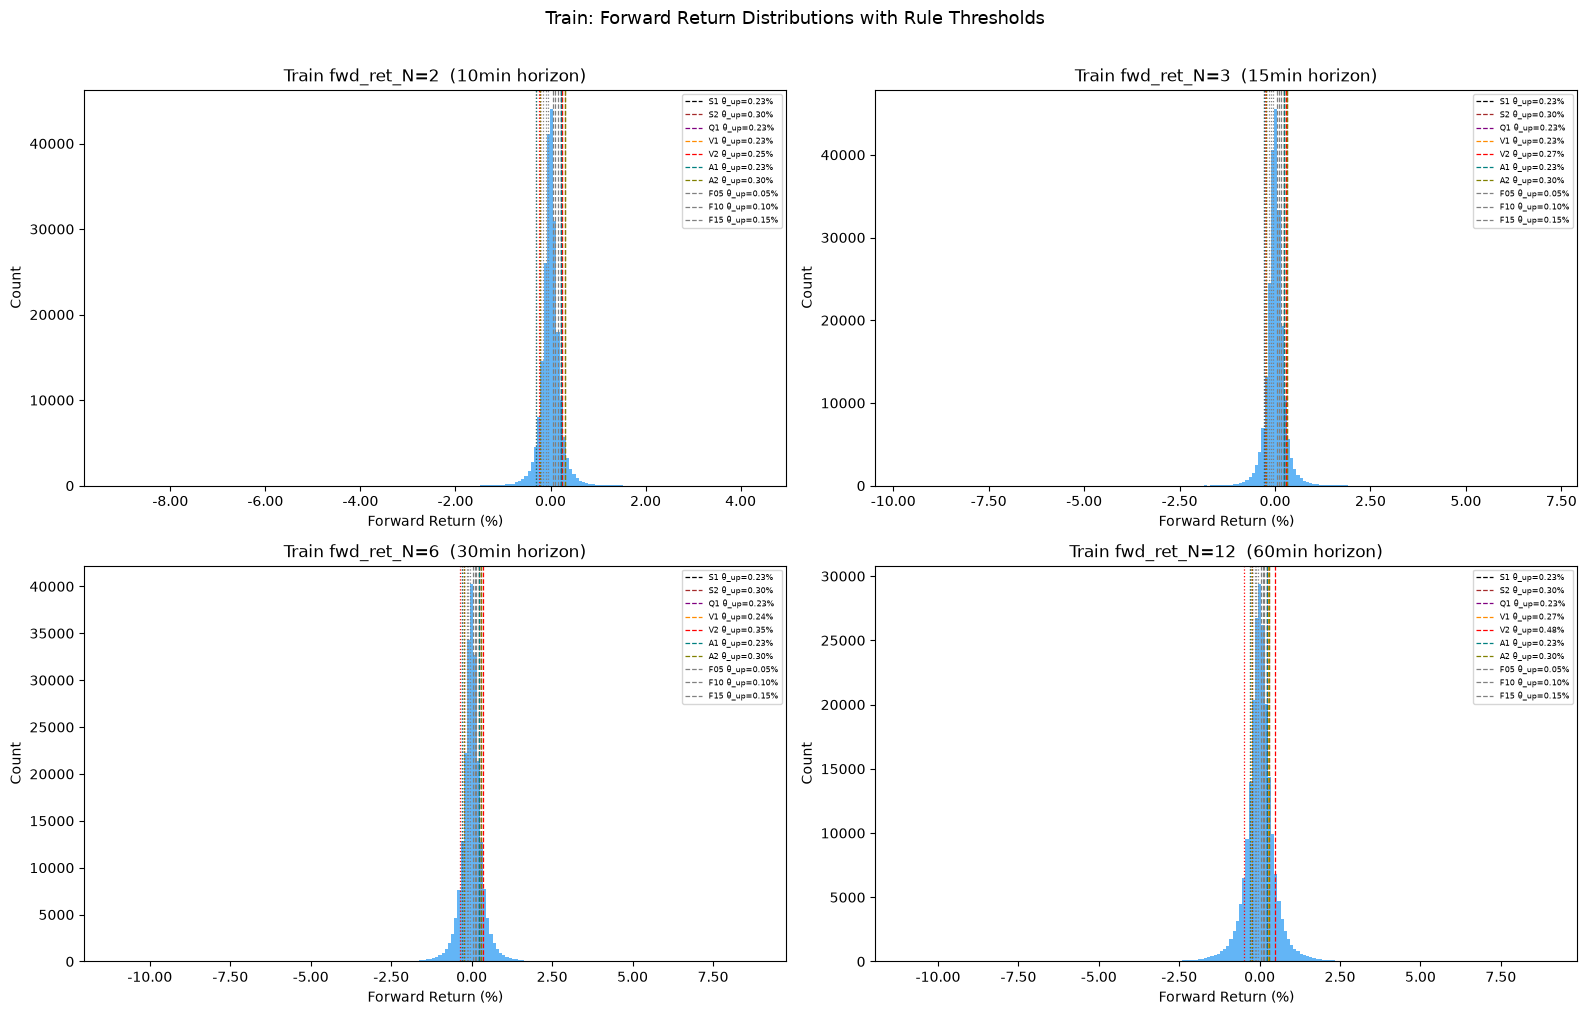

Saved: C:\B.TECH\Academics\SEMESTER V\03 Machine Learning\.ML LABs\Project\Stock-Market-ML-Indicator\ML\results\figures\02_fwd_ret_distributions.png


In [11]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
axes = axes.flatten()

for idx, N in enumerate(CANDIDATE_HORIZONS):
    ax = axes[idx]
    ret_col = f"fwd_ret_{N}"
    valid   = train_targets[f"has_valid_target_{N}"]
    ret_vals = train_targets.loc[valid, ret_col].dropna() * 100  # in %

    ax.hist(ret_vals, bins=200, color="#2196F3", alpha=0.7, edgecolor="none")
    ax.set_title(f"Train fwd_ret_N={N}  ({N*5}min horizon)")
    ax.set_xlabel("Forward Return (%)")
    ax.set_ylabel("Count")

    # Draw θ lines for each rule
    colors = {
        "S1": "black", "S2": "brown",
        "Q1": "purple", "V1": "darkorange", "V2": "red",
        "A1": "teal",   "A2": "olive",
    }
    drawn = set()
    for rule in RULES:
        col_up   = f"theta_up_{N}_{rule}"
        col_down = f"theta_down_{N}_{rule}"
        if col_up not in train_targets.columns:
            continue
        tu = train_targets.loc[valid, col_up].mean() * 100
        td = train_targets.loc[valid, col_down].mean() * 100
        c  = colors.get(rule, "gray")
        label_up   = f"{rule} θ_up={tu:.2f}%"
        label_down = f"{rule} θ_dn={td:.2f}%"
        ax.axvline(x= tu, color=c, linestyle="--", linewidth=0.9, label=label_up)
        ax.axvline(x=-td, color=c, linestyle=":",  linewidth=0.9)

    ax.legend(fontsize=6, loc="upper right")
    ax.xaxis.set_major_formatter(mticker.FormatStrFormatter("%.2f"))

plt.suptitle("Train: Forward Return Distributions with Rule Thresholds", fontsize=13, y=1.01)
plt.tight_layout()
fig_path = FIGURES_DIR / "02_fwd_ret_distributions.png"
plt.savefig(fig_path, dpi=130, bbox_inches="tight")
plt.show()
print(f"Saved: {fig_path}")


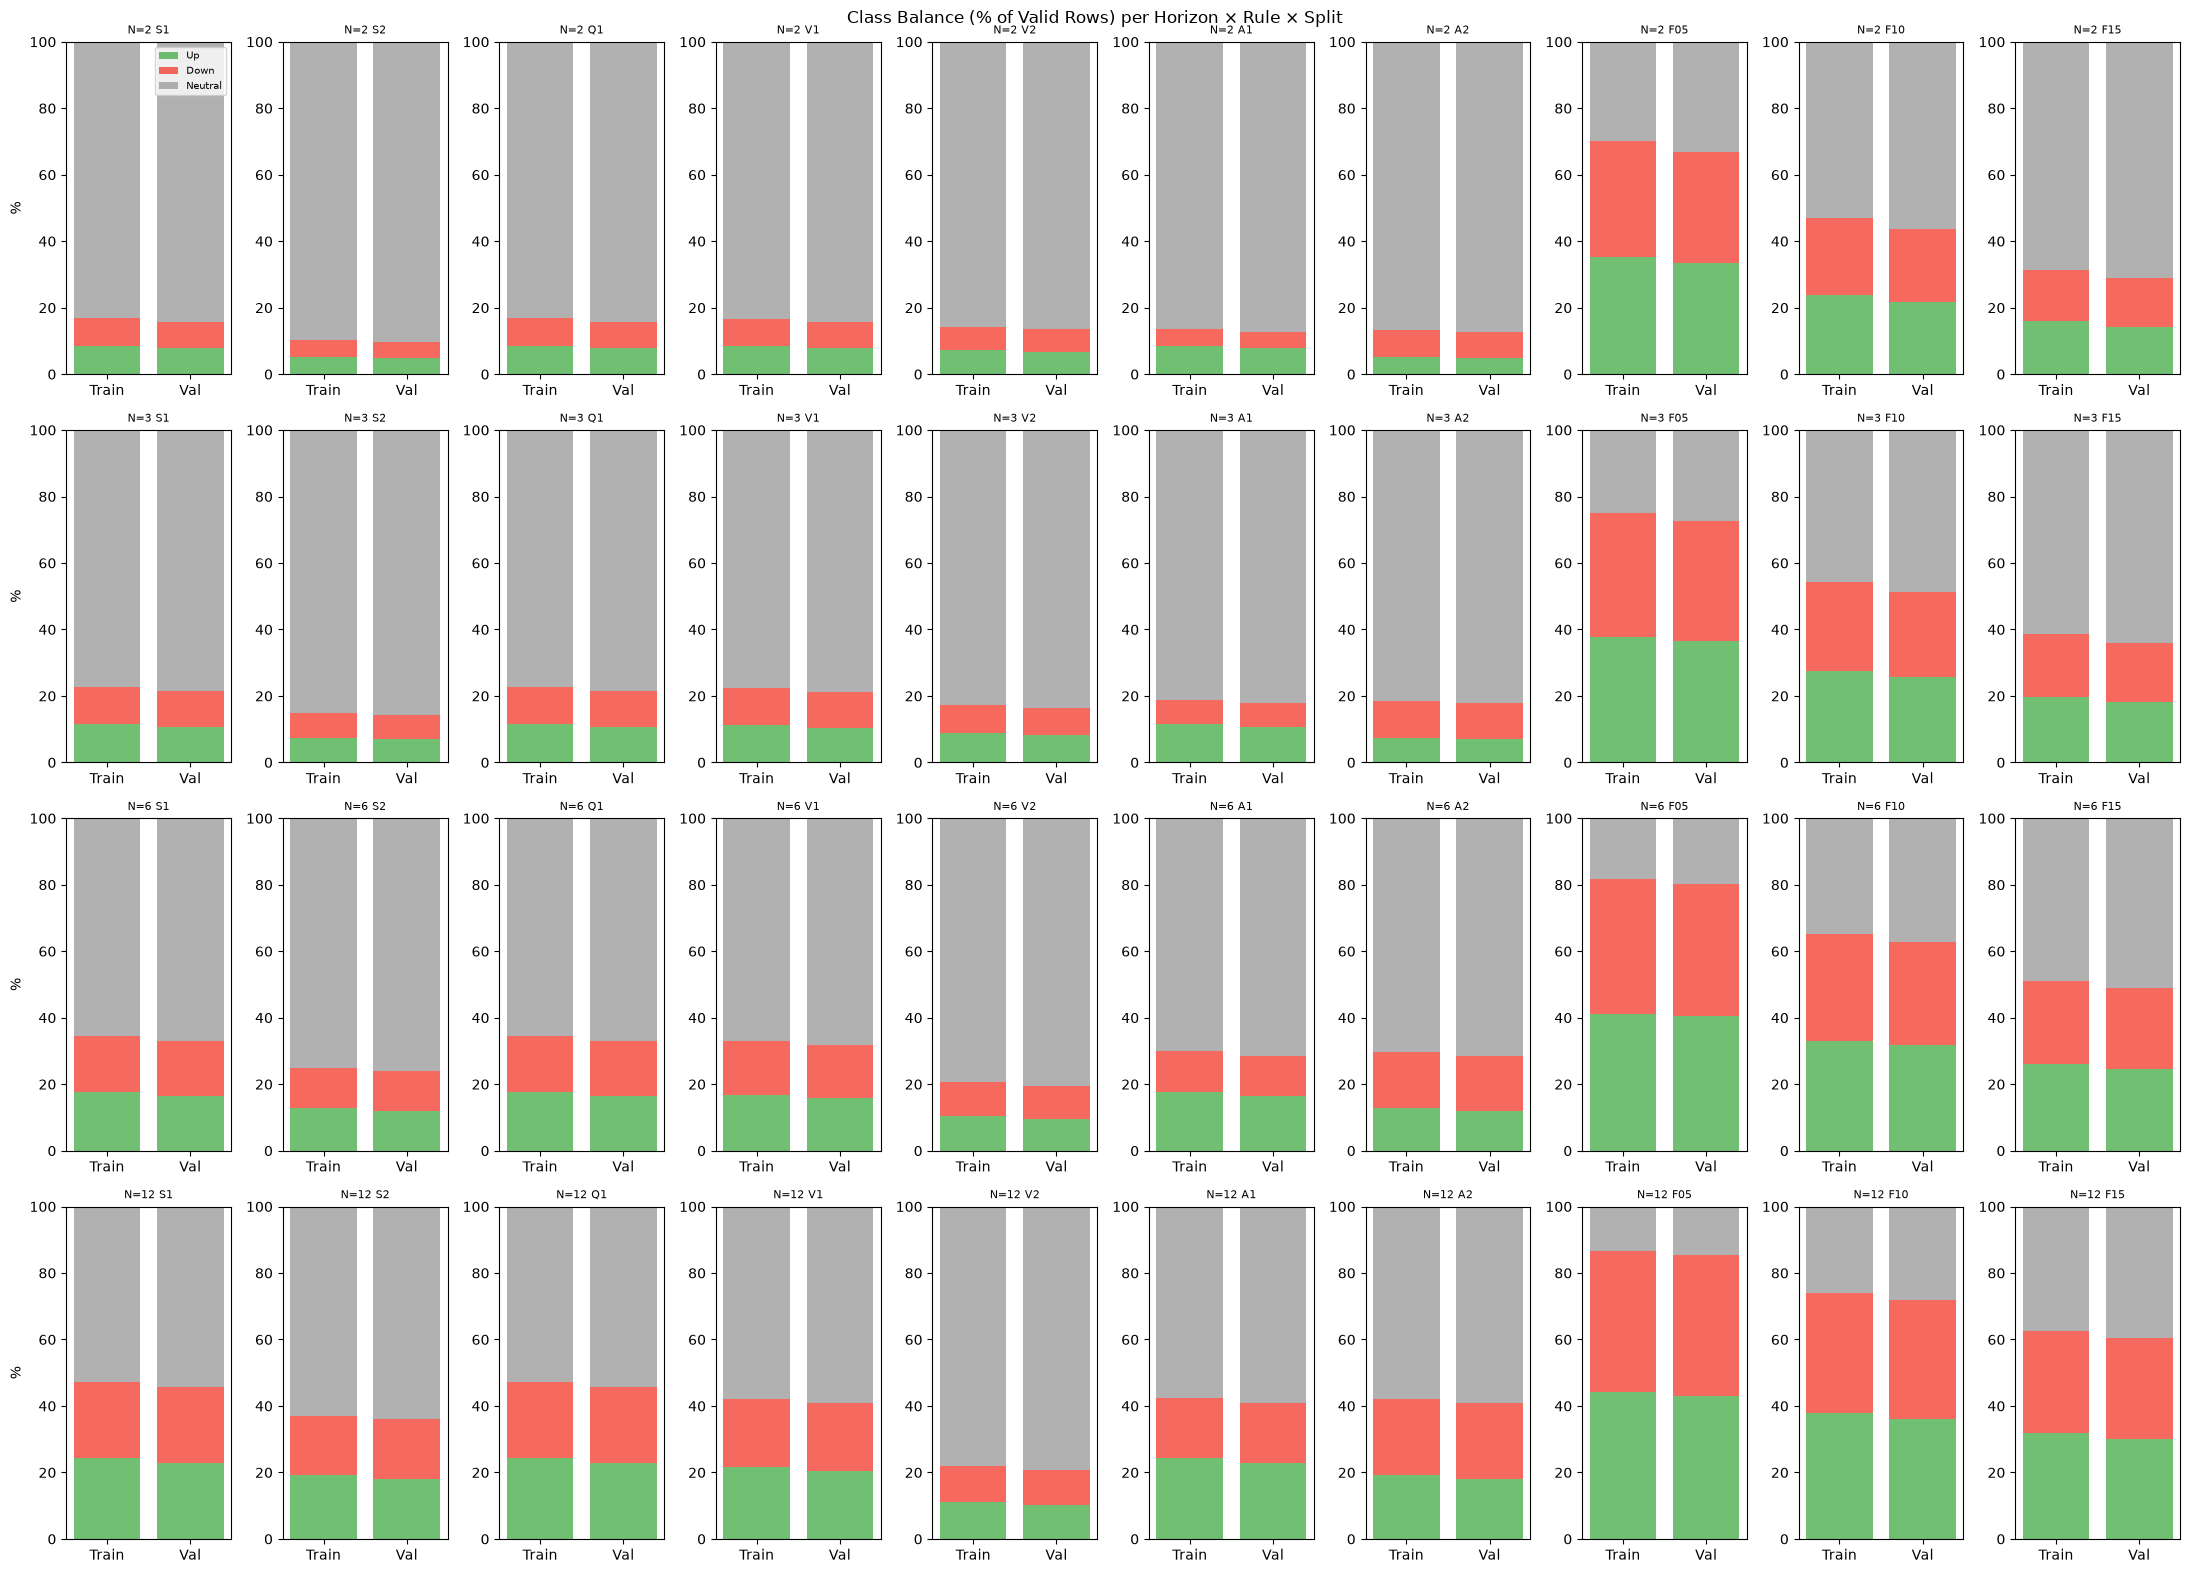

Saved: C:\B.TECH\Academics\SEMESTER V\03 Machine Learning\.ML LABs\Project\Stock-Market-ML-Indicator\ML\results\figures\02_class_balance.png


In [12]:
fig, axes = plt.subplots(len(CANDIDATE_HORIZONS), len(RULES),
                         figsize=(22, 4 * len(CANDIDATE_HORIZONS)))

for r_idx, N in enumerate(CANDIDATE_HORIZONS):
    for c_idx, rule in enumerate(RULES):
        ax = axes[r_idx][c_idx] if len(CANDIDATE_HORIZONS) > 1 else axes[c_idx]
        bars = []
        for split_name, targets_df in [("Train", train_targets), ("Val", val_targets)]:
            col = f"target_{N}_{rule}"
            if col not in targets_df.columns:
                continue
            tgt   = targets_df[col]
            valid = targets_df[f"has_valid_target_{N}"]
            tgt_v = tgt[valid]
            n_v   = len(tgt_v)
            up_pct      = (tgt_v == 1.0).sum() / n_v * 100 if n_v > 0 else 0
            down_pct    = (tgt_v == -1.0).sum() / n_v * 100 if n_v > 0 else 0
            neutral_pct = (tgt_v == 0.0).sum() / n_v * 100 if n_v > 0 else 0
            bars.append((split_name, up_pct, down_pct, neutral_pct))

        x = [b[0] for b in bars]
        ax.bar(x, [b[1] for b in bars], label="Up",      color="#4CAF50", alpha=0.8)
        ax.bar(x, [b[2] for b in bars], label="Down",    color="#F44336", alpha=0.8,
               bottom=[b[1] for b in bars])
        ax.bar(x, [b[3] for b in bars], label="Neutral", color="#9E9E9E", alpha=0.8,
               bottom=[b[1]+b[2] for b in bars])
        ax.set_title(f"N={N} {rule}", fontsize=8)
        ax.set_ylim(0, 100)
        ax.set_ylabel("%" if c_idx == 0 else "")
        if r_idx == 0 and c_idx == 0:
            ax.legend(fontsize=7)

plt.suptitle("Class Balance (% of Valid Rows) per Horizon × Rule × Split", fontsize=12)
plt.tight_layout()
fig_path2 = FIGURES_DIR / "02_class_balance.png"
plt.savefig(fig_path2, dpi=110, bbox_inches="tight")
plt.show()
print(f"Saved: {fig_path2}")


In [13]:
print("=" * 60)
print("has_valid_target COUNT VERIFICATION")
print("=" * 60)
print(f"{'Split':6s} {'N':>3s}  {'n_total':>8s} {'n_valid':>8s} {'n_invalid':>9s}")
print("-" * 42)
for split_name, targets_df, raw_df in [
    ("Train", train_targets, train_df),
    ("Val",   val_targets,   val_df),
]:
    for N in CANDIDATE_HORIZONS:
        col = f"has_valid_target_{N}"
        if col not in targets_df.columns:
            continue
        n_total   = len(targets_df)
        n_valid   = int(targets_df[col].sum())
        n_invalid = n_total - n_valid
        # Sanity: last N rows must be invalid
        last_n_valid = int(targets_df[col].iloc[-N:].sum())
        status = "OK" if last_n_valid == 0 else f"ALERT: last {N} has {last_n_valid} valid!"
        print(f"{split_name:6s} {N:>3d}  {n_total:>8,} {n_valid:>8,} {n_invalid:>9,}  {status}")


has_valid_target COUNT VERIFICATION
Split    N   n_total  n_valid n_invalid
------------------------------------------
Train    2   220,953  220,951         2  OK
Train    3   220,953  220,950         3  OK
Train    6   220,953  220,947         6  OK
Train   12   220,953  220,941        12  OK
Val      2    47,347   47,345         2  OK
Val      3    47,347   47,344         3  OK
Val      6    47,347   47,341         6  OK
Val     12    47,347   47,335        12  OK


In [14]:
from src.io_utils import (
    save_targets_base_csv,
    save_targets_labels_csv,
    save_theta_frozen_json,
    load_targets_base_csv,
    load_targets_labels_csv,
)
from src.details import describe_dataframe, write_details, describe_split_boundaries

print("Saving targets to disk via io_utils...")
# Compute targets across the entire clean dataset to persist continuous time series
all_targets = compute_all_targets(
    df, train_df=train_df,
    horizons=CANDIDATE_HORIZONS, cost=COST, q1_thresholds=q1
)

base_cols = []
for N in CANDIDATE_HORIZONS:
    base_cols.extend([f"fwd_ret_{N}", f"fwd_ret_open_{N}", f"raw_sign_{N}", f"has_valid_target_{N}"])

label_cols = []
for N in CANDIDATE_HORIZONS:
    for rule in RULES:
        label_cols.extend([f"target_{N}_{rule}", f"theta_up_{N}_{rule}", f"theta_down_{N}_{rule}"])
    label_cols.append(f"big_move_{N}")

df_base = all_targets[base_cols]
df_labels = all_targets[label_cols]

p_base = save_targets_base_csv(df_base)
p_labels = save_targets_labels_csv(df_labels)
p_theta = save_theta_frozen_json(q1, train_df, sigma_window=288)

print(f"  Saved: {p_base} ({p_base.stat().st_size:,} bytes)")
print(f"  Saved: {p_labels} ({p_labels.stat().st_size:,} bytes)")
print(f"  Saved: {p_theta} ({p_theta.stat().st_size:,} bytes)")

print("\nGenerating step02 records in details/...")
p_split = write_details("step02_split", describe_split_boundaries(df, step=2))

df_base_disk = load_targets_base_csv()
p_dt_base = write_details("step02_targets_base", describe_dataframe(
    df_base_disk, p_base, step=2, module="src.labels",
    description="Base forward returns, conservative open returns, raw direction signs, and valid target flags.",
    params={"horizons": CANDIDATE_HORIZONS, "roundtrip_cost_c": COST},
    checks={"labels_cross_gaps": 0, "last_N_rows_unlabeled": True, "dtypes_valid": True},
    full_df_stats=False,
    warnings=["Test split statistics are withheld (count and timestamps only)."]
))

df_labels_disk = load_targets_labels_csv()
p_dt_labels = write_details("step02_targets_labels", describe_dataframe(
    df_labels_disk, p_labels, step=2, module="src.labels",
    description="Classification labels, dynamic thetas, and big move binary targets across 4 horizons and 10 rules.",
    params={"horizons": CANDIDATE_HORIZONS, "rules": RULES, "roundtrip_cost_c": COST, "rolling_sigma_window_W": 288, "q1_train_frozen": q1},
    checks={"n_label_columns": 40, "n_big_move_columns": 4, "sub_cost_rules": ["F05", "F10", "F15"]},
    full_df_stats=False,
    warnings=["Q1 floor binds at c=0.23% for all candidate horizons; Q1 is identical to S1.", "Test split statistics are withheld."]
))

print(f"  Wrote: {p_split}")
print(f"  Wrote: {p_dt_base}")
print(f"  Wrote: {p_dt_labels}")


Saving targets to disk via io_utils...


2026-11-11 18:10:09 | INFO     | io_utils | Saved targets_base CSV to C:\B.TECH\Academics\SEMESTER V\03 Machine Learning\.ML LABs\Project\Stock-Market-ML-Indicator\ML\data\processed\targets_base.csv (318240 rows, 16 cols)


2026-11-11 18:11:12 | INFO     | io_utils | Saved targets_labels CSV to C:\B.TECH\Academics\SEMESTER V\03 Machine Learning\.ML LABs\Project\Stock-Market-ML-Indicator\ML\data\processed\targets_labels.csv (318240 rows, 124 cols)


2026-11-11 18:11:12 | INFO     | io_utils | Saved frozen theta JSON to C:\B.TECH\Academics\SEMESTER V\03 Machine Learning\.ML LABs\Project\Stock-Market-ML-Indicator\ML\data\processed\targets_theta_frozen.json


  Saved: C:\B.TECH\Academics\SEMESTER V\03 Machine Learning\.ML LABs\Project\Stock-Market-ML-Indicator\ML\data\processed\targets_base.csv (73,222,810 bytes)
  Saved: C:\B.TECH\Academics\SEMESTER V\03 Machine Learning\.ML LABs\Project\Stock-Market-ML-Indicator\ML\data\processed\targets_labels.csv (263,579,605 bytes)
  Saved: C:\B.TECH\Academics\SEMESTER V\03 Machine Learning\.ML LABs\Project\Stock-Market-ML-Indicator\ML\data\processed\targets_theta_frozen.json (1,869 bytes)

Generating step02 records in details/...


  Wrote: C:\B.TECH\Academics\SEMESTER V\03 Machine Learning\.ML LABs\Project\Stock-Market-ML-Indicator\ML\details\step02_split.json
  Wrote: C:\B.TECH\Academics\SEMESTER V\03 Machine Learning\.ML LABs\Project\Stock-Market-ML-Indicator\ML\details\step02_targets_base.json
  Wrote: C:\B.TECH\Academics\SEMESTER V\03 Machine Learning\.ML LABs\Project\Stock-Market-ML-Indicator\ML\details\step02_targets_labels.json


## Note: Anomaly Count Discrepancy (1,701 vs 1,718)

| Session | Dataset rows | Flagged anomalies |
|---------|-------------|-------------------|
| Prior session (unverifiable) | ~315,648 (pre-extension) | 1,701 (reported, not recomputed here) |
| Current canonical: first 315,648 rows | 315,648 | 1,690 (recomputed) |
| Current canonical: full 318,240 rows | 318,240 | **1,718** (official figure) |

The 1,701 figure came from the prior session's internal calculations on a dataset that cannot be bit-identically reproduced in the current environment. 
On the **canonical current dataset** (`clean.csv`, 318,240 rows), the official anomaly count is **1,718** (1,690 in the pre-extension slice + 28 in the 9 added days of November 2026).  
This is documented in `docs/failures.md` Log Entry 002.
